In [1]:
import pandas as pd
import matplotlib.pyplot as plt

tx = pd.read_csv("../data/raw/ieee-cis/train_transaction.csv")
ident = pd.read_csv("../data/raw/ieee-cis/train_identity.csv")

print("transactions:", tx.shape)
print("identity:", ident.shape)
print("fraud rate:", round(tx["isFraud"].mean(), 4))

transactions: (590540, 394)
identity: (144233, 41)
fraud rate: 0.035


The dataset has 590,540 transactions with 394 columns; 3.5% are fraud, so the classes are highly imbalanced and accuracy is not a useful metric. Only about 24% of transactions have identity (device) information.

In [2]:
tx["day"] = tx["TransactionDT"] // 86400
tx["week"] = tx["day"] // 7
print("first day:", tx["day"].min(), " last day:", tx["day"].max())
print("days covered:", tx["day"].max() - tx["day"].min() + 1)
print("transactions per day (avg):", round(len(tx) / tx["day"].nunique()))

first day: 1  last day: 182
days covered: 182
transactions per day (avg): 3245


The data covers 182 days (about 6 months), with an average of about 3,245 transactions per day. Times are given as seconds from a hidden reference point, so we use day numbers instead of calendar dates.

In [3]:
missing = tx.isna().mean().sort_values(ascending=False)
print("columns:", tx.shape[1])
print("columns more than 50% empty:", (missing > 0.5).sum())
missing.head(15)

columns: 396
columns more than 50% empty: 174


dist2    0.936284
D7       0.934099
D13      0.895093
D14      0.894695
D12      0.890410
D6       0.876068
D8       0.873123
D9       0.873123
V153     0.861237
V162     0.861237
V161     0.861237
V158     0.861237
V157     0.861237
V156     0.861237
V155     0.861237
dtype: float64

174 of 394 columns are more than 50% missing. Many V columns share identical missing rates (for example V153–V162 at 86%), which suggests they come in groups filled for the same transactions; we will keep a few representatives per group. Missingness is handled natively by LightGBM and filled for logistic regression.

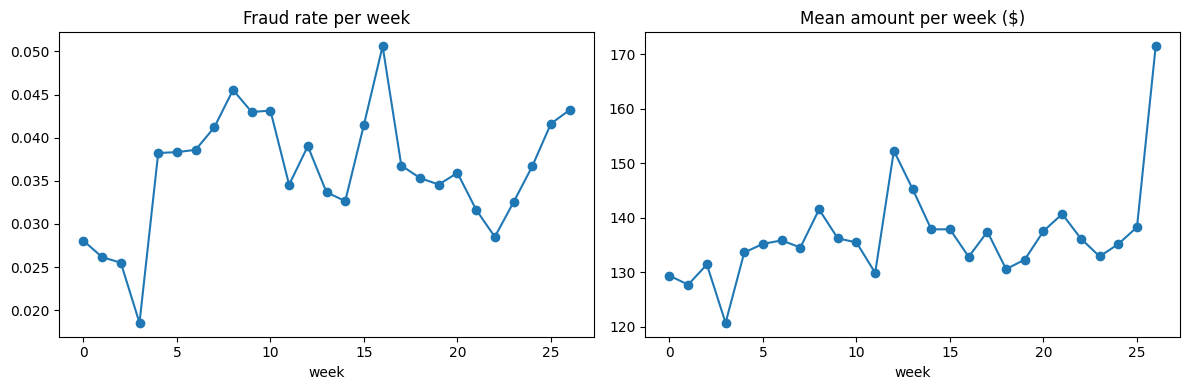

In [4]:
weekly = tx.groupby("week").agg(fraud_rate=("isFraud", "mean"),
                                mean_amount=("TransactionAmt", "mean"),
                                n=("isFraud", "size"))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
weekly["fraud_rate"].plot(ax=ax[0], marker="o", title="Fraud rate per week")
weekly["mean_amount"].plot(ax=ax[1], marker="o", title="Mean amount per week ($)")
plt.tight_layout(); plt.show()

The weekly fraud rate is not stable: it ranges from about 1.8% to 5%, with a jump around week 4, a peak at week 16 and a dip around week 22. The mean amount also shifts between weeks. This indicates drift over time, and most of it falls inside the replayed stream period (weeks 15–26). The first and last weeks are partial and should be read with care.

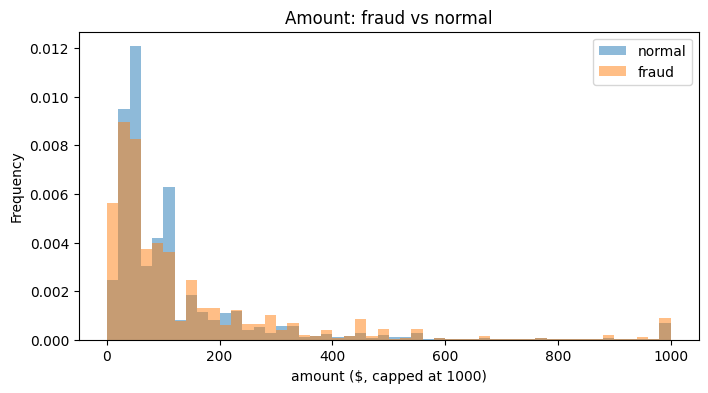

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
for label, name in [(0, "normal"), (1, "fraud")]:
    tx.loc[tx["isFraud"] == label, "TransactionAmt"].clip(upper=1000).plot.hist(
        bins=50, alpha=0.5, density=True, ax=ax, label=name)
ax.set_xlabel("amount ($, capped at 1000)"); ax.legend(); ax.set_title("Amount: fraud vs normal")
plt.show()

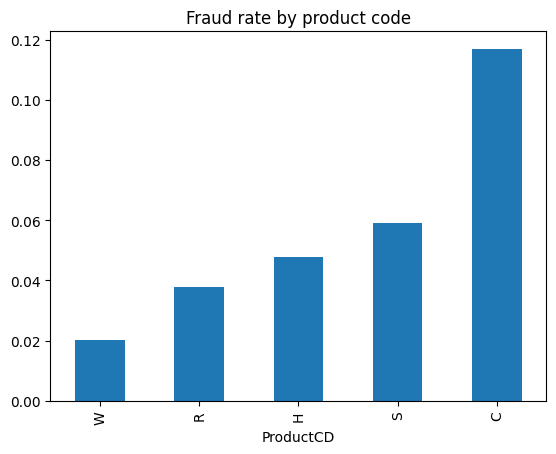

In [6]:
tx.groupby("ProductCD")["isFraud"].mean().sort_values().plot.bar(title="Fraud rate by product code")
plt.show()

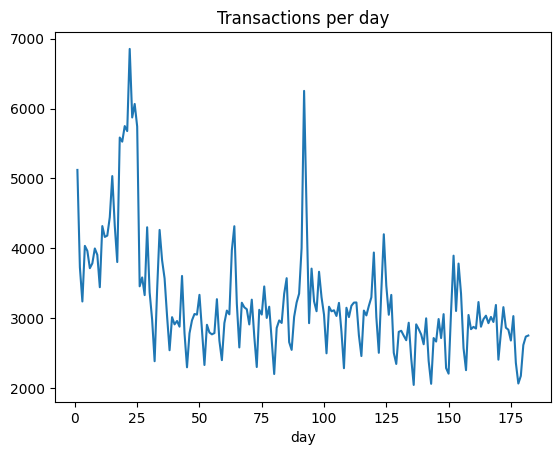

In [7]:
tx.groupby("day").size().plot(title="Transactions per day")
plt.show()

Transaction amounts overlap heavily between fraud and normal payments, though fraud is more common at very small amounts (consistent with card testing), so amount alone is a weak signal. Fraud rate varies strongly by product code (about 2% for W up to 11.7% for C). Daily volume is highest in days 15–28 and settles around 3,000 per day afterwards, so the training period contains a busy period the stream does not.